# Zero-shot MT and fine-tuning for Romagnol-Italian

In this notebook:

0. Imports & Functions & Global Variables
1. Preparing parallel dataset (parse tmx, create dataframe with sentence pairs, dataset partitioning)
2. Zero-shot translation and evaluation
3. Fine-tuning MT models
4. Fine-tuned Translation and Evaluation

*N.B. Not ready to run out of the box: adjust local paths, model names, and checkpoint directories before execution.* <br>

N.B.2 Conda and pip dependencies of the GPU environment where this pipeline was developed and run can be found in environment.yml <br>

On Trados Studio, pairs .txt and .wav in Romagnol and Italian contained in the rgn-ita subcorpus of the Romagnol corpus were aligned. All aligned segments were then imported into a translation memory (.tmx), containing 2655 translation units. <br>

Once in VScode, in **Section 1** the tmx is parsed and an automatic check for duplicates (deduplication step) and empty segments is done on the pandas dataframe created with the clean sentence pairs extracted from the tmx (stripping xml tags). No translation units needed to be removed. <br>

Length and Ratio Filtering was not performed because given the scarcity of data, sub-ideal and outlier segments (usually shorter than 3 words or over 50) were kept in the dataset. In this dataset, source segments with fewer than 3 words were around 10% and exluding so many was not an option. The majority of segments in the dataset have fewer than 50 words (only 0.15 exceeded this length).  <br>

Dataset partitioning (70-10-20, same percentages for train, dev and test set used for ASR fine-tuning):
* Romagnol-Italian Training Split (train set) (70% = 1,858 sentence pairs)
* Dev Set (10% = 266 sentence pairs)
* Test Set (20% = 531 sentence pairs)

Two baseline models (distilled *NNLB-200-600M* and *NLLB-200-1.3B*) were deployed for zero-shot translation on the test set and evaluated in **Section 2**.

The next step in the pipeline is fine-tuning in **Section 3**, which was carried out with Low-Rank Adaptation (LoRA), a parameter-efficient fine-tuning strategy, which freezes the original weights of the models and learns reduced targeted representations to optimize the neural network. Every model was trained independently three times (seeds 42, 123, and 999). Fine-tuning was carried out for both translation directions: Romagnol to Italian and Italian to Romagnol. <br>

The best checkpoint during training was chosen with chrF++ as evaluation metric. It's a character-level metric, rather than a word-level metric like BLEU, and it is usually preferred for low-resource, regional, and morphologically rich languages. chrF evaluates overlapping character n-grams (typically sequences of 1 to 6 characters), this allows it to reward partial morphological alignment and shared word stems even when exact surface forms or inflections differ. chrF++ incorporates word unigrams and bigrams alongside character n-grams (ensuring lexical adequacy and penalizing translations that get individual characters right but fail to produce complete, correct words). This metric is more resilient to subword segmentation discrepancies, minor typos, and script/encoding mismatches than token-based metrics (very useful for languages where spelling standard is not fixed). chrF also has a higher and more stable correlation with human evaluations. <br>

**In Section 4**, the fine-tuned models (3 for each model variant and for each translation direction) are used to translate the test set again in both directions. Predictions are evaluated and mean ± standard deviation is calculated for each setup. <br>

For evaluation, Bilingual Evaluation Understudy (BLEU) and Translation Error Rate (TER) are shown alongside chrF++ to give a better idea of the performance on a token and on a structural level. Additionally, BLEU is one of the most popular scores in literature, so benchmarks are frequently reported with this score, and TER is common in commercial and professional translation environments within Machine Translation Post-Editing (MTPE) workflows. <br>

References:

https://machinelearningmastery.com/develop-neural-machine-translation-system-keras/ <br>
https://blog.promptlayer.com/how-to-fine-tune-a-translation-model/ <br>
https://huggingface.co/facebook/nllb-200-distilled-600M <br>
https://huggingface.co/facebook/nllb-200-distilled-1.3B <br>

## 0. Imports & Functions & Global Variables

In [ ]:
import functools
import gc
import json
import os
from pathlib import Path
import shutil
import statistics
import tempfile
import types
from typing import Dict, List, Optional
import xml.etree.ElementTree as ET
import ctranslate2
from ctranslate2.converters import TransformersConverter
from datasets import Dataset
import evaluate
from huggingface_hub import snapshot_download
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from peft import LoraConfig, PeftModelForSeq2SeqLM, TaskType, get_peft_model
import torch
from tqdm import tqdm as std_tqdm
from transformers import (
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
    NllbTokenizerFast,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    set_seed,
)
from translate.storage.tmx import tmxfile

/home/ialiani/.conda/envs/asr_env/lib/python3.10/site-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


In [ ]:
def env_check():
    """
    Checks environment where notebook is being run. 
    """
    # If CUDA is present and has at least 4 GB free, use GPU; otherwise CPU
    free_vram = torch.cuda.mem_get_info(0)[0] / (1024 ** 3) if torch.cuda.is_available() else 0
    use_gpu = free_vram >= 4.0

    device = "cuda" if use_gpu else "cpu"
    compute_type = "float16" if use_gpu else "int8"

    print(f"Target: {device.upper()} | Compute: {compute_type} (Free VRAM: {free_vram:.1f} GB)")
    return use_gpu, device, compute_type

def parse_tmx(tmx_path: str, src_lang: str = "rgn", tgt_lang: str = "it") -> pd.DataFrame:
    """
    Parses .tmx file with parallel data, creates a dataframe with it, drops duplicates if present.
    """
    with open(tmx_path, "rb") as f:
        tmx = tmxfile(f, src_lang, tgt_lang)

    pairs = [
        {
            "Romagnol": unit.source.strip(),
            "Italian": unit.target.strip()
        }
        for unit in tmx.units
        if unit.source and unit.target
    ]

    return pd.DataFrame(pairs).drop_duplicates().reset_index(drop=True)

def tmx_quality_stats(tmx_path: str) -> tuple[float, float, int]:
    """
    Extract quality scores from original .tmx file.
    """
    tree = ET.parse(tmx_path)
    
    
    scores = [
        int(prop.text)
        for prop in tree.iter("prop")
        if prop.attrib.get("type") == "x-Quality:Integer" and prop.text
    ]
    
    n = len(scores)
    if n == 0:
        return 0.0, 0.0, 0
    if n == 1:
        return float(scores[0]), 0.0, 1
    
    mean_val = statistics.mean(scores)
    std_val = statistics.stdev(scores)  # Sample standard deviation (N - 1)
    
    return mean_val, std_val, n


def count_segment_length_outliers(tmx_path: str, min_words: int = 3, max_words: int = 50) -> dict:
    """
    Calculates segment length.
    """
    tree = ET.parse(tmx_path)
    under_min = 0
    over_max = 0
    total = 0
    for tu in tree.iter("tu"):
        first_tuv = tu.find("tuv")  # The source segment is the first <tuv> inside each translation unit
        if first_tuv is None:
            continue
        seg = first_tuv.find("seg")
        if seg is None:
            continue
        text = "".join(seg.itertext()).strip()
        if not text:
            continue
        total += 1
        word_count = len(text.split())
        if word_count < min_words:
            under_min += 1
        elif word_count > max_words:
            over_max += 1
    return {
        "total_source_segments": total,
        f"under_{min_words}_words": under_min,
        f"over_{max_words}_words": over_max,
        f"pct_under_{min_words}": (under_min / total * 100) if total else 0.0,
        f"pct_over_{max_words}": (over_max / total * 100) if total else 0.0,
    }


def setup_nllb_model(model_name: str, output_dir: str = None) -> str:
    """
    Downloads weights for NLLB-200 model variants.
    """
    if output_dir is None:
        output_dir = Path.home() / "thesis_Aliani" / f"{model_name.replace('/', '_')}_weights"
    output_dir = Path(output_dir)

    if not (output_dir / "model.bin").is_file():
        print(f"Downloading and converting '{model_name}'...")
        local_path = snapshot_download(repo_id=model_name, cache_dir=str(USER_CACHE))

        converter = TransformersConverter(local_path)
        converter.convert(output_dir=str(output_dir), quantization="float16")

        # Save ONLY the tokenizer (do NOT save AutoConfig here, as it overwrites CTranslate2's config.json)
        NllbTokenizerFast.from_pretrained(local_path).save_pretrained(str(output_dir))

        shutil.rmtree(local_path, ignore_errors=True)
    else:
        print(f"Found existing weights in: {output_dir}")

    return str(output_dir)


def load_nllb_model(model_path, device="cuda", compute_type="float16"):
    """
    Loads a model into a translator object.
    """
    model_path = Path(model_path)
    threads = (os.cpu_count() or 4) if device == "cpu" else 0
    translator = ctranslate2.Translator(
        str(model_path),
        device=device,
        compute_type=compute_type,
        intra_threads=threads,
    )

    # Fix v5-style list `extra_special_tokens` in local tokenizer_config.json if present
    tok_cfg = model_path / "tokenizer_config.json"
    if tok_cfg.exists():
        cfg = json.loads(tok_cfg.read_text(encoding="utf-8"))
        if isinstance(cfg.get("extra_special_tokens"), list):
            cfg.pop("extra_special_tokens")
            tok_cfg.write_text(json.dumps(cfg, indent=2), encoding="utf-8")

    tokenizer = NllbTokenizerFast.from_pretrained(str(model_path))
    return translator, tokenizer


def translate_dataframe(translator, tokenizer, test_df: pd.DataFrame, src_col: str, src_lang: str, tgt_lang: str, output_csv: str = None, batch_size: int = 32) -> list[str]:
    """
    Translates a column of test_df in batches using CTranslate2,
    returns predictions, and optionally saves the updated DataFrame to CSV.
    """
    tokenizer.src_lang = src_lang
    texts = test_df[src_col].tolist()
    predictions = []

    for i in std_tqdm(range(0, len(texts), batch_size), desc="Translating batches", unit="batch"):
        batch_texts = texts[i : i + batch_size]

        # Convert input sentences to subword tokens
        source_tokens = [
            tokenizer.convert_ids_to_tokens(tokenizer.encode(text))
            for text in batch_texts
        ]
        target_prefixes = [[tgt_lang]] * len(batch_texts)

        # Translate batch with beam_size=5
        results = translator.translate_batch(
            source_tokens,
            target_prefix=target_prefixes,
            beam_size=5
        )

        # Strip the leading target language token and decode back to string
        for res in results:
            hyp_tokens = res.hypotheses[0]
            if hyp_tokens and hyp_tokens[0] == tgt_lang:
                hyp_tokens = hyp_tokens[1:]
            decoded = tokenizer.decode(
                tokenizer.convert_tokens_to_ids(hyp_tokens),
                skip_special_tokens=True
            )
            predictions.append(decoded)

    if output_csv is not None:
        out_path = Path(output_csv)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        df_out = test_df.copy()
        df_out["prediction"] = predictions
        df_out.to_csv(out_path, index=False, encoding="utf-8")

    return predictions

def build_direction_datasets(train_df, dev_df, tokenizer_dir: str, direction: str = "rgn2it", max_length: int = 128):
    """
    Tokenizes train_df and dev_df in memory for a specific translation direction.
    direction: 'rgn2it' (Romagnol -> Italian) or 'it2rgn' (Italian -> Romagnol)
    """
    if direction == "rgn2it":
        src_col, tgt_col = "Romagnol", "Italian"
        src_lang, tgt_lang = "lmo_Latn", "ita_Latn"
    elif direction == "it2rgn":
        src_col, tgt_col = "Italian", "Romagnol"
        src_lang, tgt_lang = "ita_Latn", "lmo_Latn"
    else:
        raise ValueError("direction must be 'rgn2it' or 'it2rgn'")

    # Load tokenizer offline from your saved weights directory
    tokenizer = NllbTokenizerFast.from_pretrained(
        tokenizer_dir,
        src_lang=src_lang,
        tgt_lang=tgt_lang,
    )

    def tokenize_fn(batch):
        return tokenizer(
            batch[src_col],
            text_target=batch[tgt_col],
            max_length=max_length,
            truncation=True,
        )

    # Convert pandas DataFrames to HF Datasets and strip raw text columns
    train_ds = Dataset.from_pandas(train_df).map(
        tokenize_fn,
        batched=True,
        remove_columns=list(train_df.columns),
    )
    dev_ds = Dataset.from_pandas(dev_df).map(
        tokenize_fn,
        batched=True,
        remove_columns=list(dev_df.columns),
    )

    return train_ds, dev_ds, tokenizer



def build_compute_metrics(tokenizer):
    """
    Computes BLEU and chrF++ during Seq2SeqTrainer evaluation.
    """
    def compute_metrics(pred):
        pred_ids, label_ids = pred.predictions, pred.label_ids
        if isinstance(pred_ids, tuple):
            pred_ids = pred_ids[0]

        label_ids = np.where(label_ids != -100, label_ids, tokenizer.pad_token_id)

        pred_str = tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
        label_str = tokenizer.batch_decode(label_ids, skip_special_tokens=True)
        refs = [[l] for l in label_str]

        bleu = bleu_metric.compute(predictions=pred_str, references=refs)["score"]
        chrf = chrf_metric.compute(predictions=pred_str, references=refs, word_order=2)["score"]

        return {"bleu": round(bleu, 2), "chrf++": round(chrf, 2)}

    return compute_metrics


class CleanSeq2SeqCollator(DataCollatorForSeq2Seq):
    """
    Guarantees decoder_input_ids is always shifted from labels (even when Trainer pops labels for label smoothing).
    """

    def __call__(self, features, return_tensors=None):
        """
        Collates batch features and manually creates right-shifted decoder_input_ids if missing.
        """
        batch = super().__call__(features, return_tensors=return_tensors)
        if "labels" in batch and "decoder_input_ids" not in batch:
            # NLLB / M2M100 shifts labels right using decoder_start_token_id (2 = </s>) and pad_token_id (1)
            labels = batch["labels"]
            decoder_start_token_id = self.model.config.decoder_start_token_id
            pad_token_id = self.tokenizer.pad_token_id

            shifted = labels.new_zeros(labels.shape)
            shifted[:, 1:] = labels[:, :-1].clone()
            shifted[:, 0] = decoder_start_token_id
            shifted.masked_fill_(shifted == -100, pad_token_id)
            batch["decoder_input_ids"] = shifted
        return batch


def apply_lora(model):
    """
    Applies LoRA (r=16, alpha=32, dropout=0.05) and strips decoder_inputs_embeds cleanly.
    """
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_2_SEQ_LM,
        r=16,
        lora_alpha=32,
        lora_dropout=0.05,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
    )
    peft_model = get_peft_model(model, lora_config)

    # Override forward on this exact instance so PeftModelForSeq2SeqLM never injects decoder_inputs_embeds=None
    def _forward(
        input_ids=None,
        attention_mask=None,
        inputs_embeds=None,
        decoder_input_ids=None,
        decoder_inputs_embeds=None,
        labels=None,
        output_attentions=None,
        output_hidden_states=None,
        return_dict=None,
        task_ids=None,
        **kwargs,
    ):
        return peft_model.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            inputs_embeds=inputs_embeds,
            decoder_input_ids=decoder_input_ids,
            labels=labels,
            output_attentions=output_attentions,
            output_hidden_states=output_hidden_states,
            return_dict=return_dict,
            **kwargs,
        )

    peft_model.forward = _forward
    peft_model.print_trainable_parameters()
    return peft_model


def get_lora_training_args(model_name: str, direction: str, seed: int, generation_config=None, max_steps: int = 1500, eval_steps: int = 100, per_device_batch_size: int = 8, grad_accum_steps: int = 4):
    """
    Creates checkpoint directories and configures Seq2SeqTrainingArguments for LoRA fine-tuning.
    """
    path = Path.home() / "thesis_Aliani" / "checkpoints" / f"{model_name}_lora" / direction / f"seed_{seed}"
    path.mkdir(parents=True, exist_ok=True)

    return Seq2SeqTrainingArguments(
        output_dir=str(path),
        max_steps=max_steps,
        per_device_train_batch_size=per_device_batch_size,
        gradient_accumulation_steps=grad_accum_steps,
        per_device_eval_batch_size=per_device_batch_size,
        learning_rate=1e-4,
        weight_decay=0.01,
        lr_scheduler_type="linear",
        warmup_steps=max(1, round(0.1 * max_steps)),
        label_smoothing_factor=0.1,
        optim="adamw_bnb_8bit",
        seed=seed,
        data_seed=seed,
        fp16=True,
        remove_unused_columns=False,
        predict_with_generate=True,
        generation_config=generation_config,
        eval_strategy="steps",
        eval_steps=eval_steps,
        save_strategy="steps",
        save_steps=eval_steps,
        save_total_limit=2,
        logging_steps=25,
        report_to=["tensorboard"],
        metric_for_best_model="chrf++",
        greater_is_better=True,
        load_best_model_at_end=True,
    )


def export_lora_to_ct2(trainer, tokenizer, model_tag: str, direction: str, seed: int):
    """
    LoRA fine-tuned weights are converted into CTranslate2 weights 
    (significantly smaller on disk and in VRAM than standard PyTorch / Hugging Face checkpoints).
    """
    ct2_output_dir = Path.home() / "thesis_Aliani" / f"{model_tag}_{direction}_seed{seed}_finetuned_weights"
    if ct2_output_dir.exists():
        shutil.rmtree(ct2_output_dir)

    # Merge LoRA weights in memory and save intermediate HF files to /tmp
    merged_model = trainer.model.merge_and_unload()
    with tempfile.TemporaryDirectory(dir="/tmp", prefix=f"ct2_merge_{model_tag}_") as tmp_dir:
        merged_model.save_pretrained(tmp_dir)
        tokenizer.save_pretrained(tmp_dir)

        converter = TransformersConverter(tmp_dir)
        converter.convert(output_dir=str(ct2_output_dir), quantization="float16")
        tokenizer.save_pretrained(str(ct2_output_dir))

    # Remove intermediate LoRA checkpoints after converting them to CTranslate2
    ckpt_dir = Path(trainer.args.output_dir)
    if ckpt_dir.exists():
        shutil.rmtree(ckpt_dir, ignore_errors=True)

    return str(ct2_output_dir)


def evaluate_predictions(references: List[str], hypotheses: List[str]) -> Dict[str, float]:
    """
    Evaluation on test_df predictions using BLEU, chrF++, and TER. 
    Used both for zero-shot results and for results obtained with fine-tuned models. 
    """
    if len(references) != len(hypotheses):
        raise ValueError(f"Length mismatch: {len(references)} vs {len(hypotheses)}.")

    clean_refs, clean_hyps = [], []
    for r, h in zip(references, hypotheses):
        r_str, h_str = str(r).strip(), str(h).strip()
        if r_str:
            clean_refs.append([r_str])
            clean_hyps.append(h_str)

    bleu = bleu_metric.compute(predictions=clean_hyps, references=clean_refs)["score"]
    chrf = chrf_metric.compute(predictions=clean_hyps, references=clean_refs, word_order=2)["score"]
    ter = ter_metric.compute(predictions=clean_hyps, references=clean_refs)["score"]

    return {
        "bleu": round(bleu, 2),
        "chrf++": round(chrf, 2),
        "ter": round(ter, 2),
        "samples": len(clean_refs),
    }

In [3]:
is_cuda, device, compute_type = env_check()

Target: CUDA | Compute: float16 (Free VRAM: 30.8 GB)


In [4]:
BASE_DIR = Path.home() / "thesis_Aliani" # Base project folder on the server

# Set cache directories to your personal user storage
USER_CACHE = Path.home() / "thesis_Aliani" / ".cache" / "huggingface"
USER_CACHE.mkdir(parents=True, exist_ok=True)

# - - - - - - - - - - - - - - - - - - - - - - - - 
is_cuda, device, compute_type = env_check()

# - - - - - - - - - - - - - - - - - - - - - - - - 

bleu_metric = evaluate.load("sacrebleu")
chrf_metric = evaluate.load("chrf")
ter_metric = evaluate.load("ter")

Target: CUDA | Compute: float16 (Free VRAM: 30.8 GB)


## 1. Preparing dataset

In [5]:
# Load and inspect dataset
df_all_tus = parse_tmx("export_rgn-ita.tmx", src_lang="rgn", tgt_lang="it")
print(f"Extracted {len(df_all_tus)} sentence pairs.")
print(df_all_tus.head())

Extracted 2655 sentence pairs.
                                            Romagnol  \
0                                          l'adelina   
1  l'adelina ch'la liziva al cherti la faseva di ...   
2  la duveva lasè e' lasit ad lez al cherti l'ims...   
3                  a n'é sò a chi ch'la se sipa lasè   
4  a sò che ciuma par truvè al malatij dla zenta ...   

                                             Italian  
0                                          l'adelina  
1  l'adelina che leggeva le carte di cognome face...  
2  doveva lasciare il lascito di leggere le carte...  
3                     non so a chi lo abbia lasciato  
4  so che ciuma per individuare le malattie della...  


In [6]:
# Usage
mean, std, count = tmx_quality_stats("export_rgn-ita.tmx")
print(f"Quality Score: {mean:.2f} ± {std:.2f}")

Quality Score: 90.65 ± 3.01


In [7]:
# Usage
results = count_segment_length_outliers("export_rgn-ita.tmx", min_words=3, max_words=50)
print(results)

{'total_source_segments': 2655, 'under_3_words': 268, 'over_50_words': 4, 'pct_under_3': 10.094161958568739, 'pct_over_50': 0.15065913370998116}


In [ ]:
# Shuffle the DataFrame reproducibly because seed 42 is fixed.
df_shuffled = df_all_tus.sample(frac=1.0, random_state=42).reset_index(drop=True)

# Compute index split points to obtain 70% of data in train, 10% in dev, and 20% in test set. 
n_total = len(df_shuffled)
train_end = int(0.70 * n_total)
dev_end = int(0.80 * n_total)  # 70% train + 10% dev = 80% mark

# Slice the partitions
train_df = df_shuffled.iloc[:train_end].reset_index(drop=True)
dev_df   = df_shuffled.iloc[train_end:dev_end].reset_index(drop=True)
test_df  = df_shuffled.iloc[dev_end:].reset_index(drop=True)

# Verify partition counts and proportions
print(f"Total: {n_total}")
print(f"Train: {len(train_df)} ({len(train_df) / n_total:.1%})")
print(f"Dev:   {len(dev_df)} ({len(dev_df) / n_total:.1%})")
print(f"Test:  {len(test_df)} ({len(test_df) / n_total:.1%})")


Total: 2655
Train: 1858 (70.0%)
Dev:   266 (10.0%)
Test:  531 (20.0%)


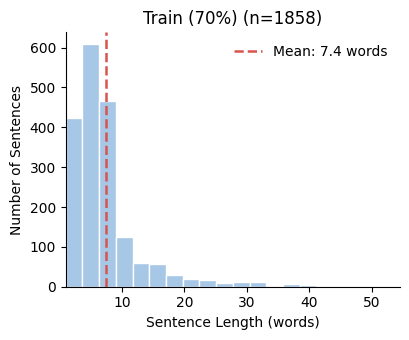

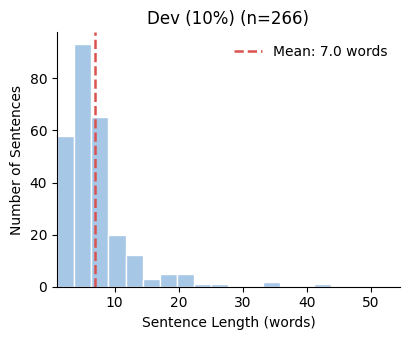

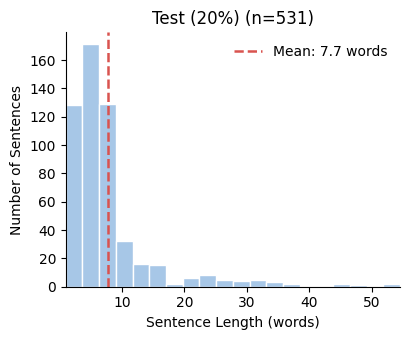

In [ ]:
# Run this cell to plot histograms showing distribution of sentence length in the three dataset partitions.
splits = [
    ("Train (70%)", train_df, "sentence_lengths_train.pdf"),
    ("Dev (10%)", dev_df, "sentence_lengths_dev.pdf"),
    ("Test (20%)", test_df, "sentence_lengths_test.pdf"),
]

# Pre-compute lengths so all three plots share identical bin edges and x-axis limits
all_lengths = {
    name: (df.iloc[:, 0].astype(str).str.split().str.len() +
           df.iloc[:, 1].astype(str).str.split().str.len()) / 2
    for name, df, _ in splits
}
global_min = min(s.min() for s in all_lengths.values())
global_max = max(s.max() for s in all_lengths.values())
bins = np.linspace(global_min, global_max, 21)  # 20 equal-width bins across all splits

for name, df, filename in splits:
    fig, ax = plt.subplots(figsize=(4.2, 3.5))
    lengths = all_lengths[name]
    mean_val = lengths.mean()

    ax.hist(lengths, bins=bins, color="#A7C7E7", edgecolor="white")
    ax.axvline(mean_val, color="#D9534F", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.1f} words")

    ax.set_title(f"{name} (n={len(df)})")
    ax.set_xlabel("Sentence Length (words)")
    ax.set_ylabel("Number of Sentences")
    ax.set_xlim(global_min, global_max)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.savefig(filename, bbox_inches="tight")
    plt.show()

## 2. Zero-shot translation and evaluation

Bidirectional translation: rgn-ita and ita-rgn, with both distilled NLLB models. = 4 zero-shot runs in total.

When translating from rgn to ita, the models can often guess the meaning of Romagnol source text through lexical overlap with Lombard, the dialect chosen as an intermediary because Romagnol is not listed as a possible language. <br>
Dialect-generation gap:  in $\text{ita} \rightarrow \text{rgn}$, forcing lmo_Latn on the decoder produces Lombard rather than authentic Romagnol orthography and morphology. <br> 
With fine-tuning, the results obtained when translating ita-rgn should improve drastically. 

In [12]:
# --- Configure Baseline Models ---
BASELINE_MODELS = [
    ("facebook/nllb-200-distilled-600M", "nllb-600m"),
    ("facebook/nllb-200-distilled-1.3B", "nllb-1.3b"),
]

DIRECTIONS = [
    ("rgn2it", "Romagnol", "Italian", "lmo_Latn", "ita_Latn"),
    ("it2rgn", "Italian", "Romagnol", "ita_Latn", "lmo_Latn"),
]
# ---------------------------------

results_dir = Path.home() / "thesis_Aliani" / "MT_results"
results_dir.mkdir(parents=True, exist_ok=True)

baseline_records = []

for model_id, model_tag in BASELINE_MODELS:
    print(f"\n{'='*60}\nLoading Zero-Shot Model: {model_id}\n{'='*60}")
    weights_dir = setup_nllb_model(model_id)
    translator, tokenizer = load_nllb_model(
        weights_dir, device=device, compute_type=compute_type
    )

    for dir_tag, src_col, ref_col, src_lang, tgt_lang in DIRECTIONS:
        output_csv = results_dir / f"{model_tag}_zeroshot_{dir_tag}.csv"
        print(f"\nTranslating {model_tag} | {dir_tag} ({src_lang} -> {tgt_lang})...")

        preds = translate_dataframe(
            translator=translator,
            tokenizer=tokenizer,
            test_df=test_df,
            src_col=src_col,
            src_lang=src_lang,
            tgt_lang=tgt_lang,
            output_csv=output_csv,
        )

        scores = evaluate_predictions(
            references=test_df[ref_col].tolist(),
            hypotheses=preds,
        )
        baseline_records.append({
            "model": model_tag,
            "direction": dir_tag,
            "bleu": scores["bleu"],
            "chrf++": scores["chrf++"],
            "ter": scores["ter"],
            "samples": scores["samples"],
        })
        print(
            f"-> {model_tag} ({dir_tag}) | "
            f"BLEU: {scores['bleu']:.2f} | chrF++: {scores['chrf++']:.2f} | TER: {scores['ter']:.2f}"
        )

    # Free GPU/CPU memory before loading the next model
    del translator, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

zeroshot_summary_df = pd.DataFrame(baseline_records)
summary_path = results_dir / "zeroshot_baselines_summary.csv"
zeroshot_summary_df.to_csv(summary_path, index=False)

print(f"\n{'='*60}\nZERO-SHOT BASELINE SUMMARY\n{'='*60}")
print(zeroshot_summary_df.to_string(index=False))
print(f"\nSaved summary table to: {summary_path}")


Loading Zero-Shot Model: facebook/nllb-200-distilled-600M
Found existing weights in: /home/ialiani/thesis_Aliani/facebook_nllb-200-distilled-600M_weights


The tokenizer you are loading from '/home/ialiani/thesis_Aliani/facebook_nllb-200-distilled-600M_weights' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.



Translating nllb-600m | rgn2it (lmo_Latn -> ita_Latn)...


Translating batches: 100%|██████████| 17/17 [00:04<00:00,  3.77batch/s]


-> nllb-600m (rgn2it) | BLEU: 8.18 | chrF++: 31.46 | TER: 87.95

Translating nllb-600m | it2rgn (ita_Latn -> lmo_Latn)...


Translating batches: 100%|██████████| 17/17 [00:03<00:00,  4.63batch/s]


... (3 outputs left out)

Translating batches: 100%|██████████| 17/17 [00:07<00:00,  2.34batch/s]


-> nllb-1.3b (rgn2it) | BLEU: 8.49 | chrF++: 32.87 | TER: 82.49

Translating nllb-1.3b | it2rgn (ita_Latn -> lmo_Latn)...


Translating batches: 100%|██████████| 17/17 [00:08<00:00,  1.91batch/s]


-> nllb-1.3b (it2rgn) | BLEU: 2.37 | chrF++: 20.73 | TER: 96.94

ZERO-SHOT BASELINE SUMMARY
    model direction  bleu  chrf++   ter  samples
nllb-600m    rgn2it  8.18   31.46 87.95      531
nllb-600m    it2rgn  1.88   21.03 89.82      531
nllb-1.3b    rgn2it  8.49   32.87 82.49      531
nllb-1.3b    it2rgn  2.37   20.73 96.94      531

Saved summary table to: /home/ialiani/thesis_Aliani/MT_results/zeroshot_baselines_summary.csv


## 3. Fine-tuning MT models
Preparing train and dev partitions for both directions + a NllbTokenizerFast instance configured with each direction's src_lang and tgt_lang tags (lmo_Latn and ita_Latn). <br>
4 x 3 fine-tuned runs: 2 models $\times$ 2 directions. Three independent runs for each setup. <br>

LoRA Fine-Tuning Hyperparameter Configurations and Optimization Arguments:

| Hyperparameter | Argument | Value |
| :--- | :--- | :---: |
| **LoRA Adapter Configuration** | | |
| Task type | `task_type` | `SEQ_2_SEQ_LM` |
| Rank ($r$) | `r` | 16 |
| Scaling factor ($\alpha$) | `lora_alpha` | 32 |
| Dropout rate | `lora_dropout` | 0.05 |
| Bias adaptation | `bias` | `none` |
| Target modules | `target_modules` | `q_proj`, `k_proj`, `v_proj`, `out_proj`, `fc1`, `fc2` |
| **Optimization, Regularization & Training Setup** | | |
| Per-device train batch size | `per_device_train_batch_size` | 8 |
| Gradient accumulation steps | `gradient_accumulation_steps` | 4 |
| Effective batch size | — | 32 |
| Per-device eval batch size | `per_device_eval_batch_size` | 8 |
| Learning rate ($\eta$) | `learning_rate` | $1.0 \times 10^{-4}$ |
| Weight decay | `weight_decay` | 0.01 |
| Label smoothing | `label_smoothing_factor` | 0.1 |
| Learning rate schedule | `lr_scheduler_type` | Linear decay |
| Warmup steps | `warmup_steps` | 150 (10% of `max_steps`) |
| Maximum training steps | `max_steps` | 1500 |
| Optimizer | `optim` | `adamw_bnb_8bit` |
| Precision | `fp16` | True (Mixed Precision) |
| **Evaluation, Checkpointing & Logging** | | |
| Random seed / Data seed | `seed` / `data_seed` | Multi-seed (42, 123, 999) |
| Evaluation strategy | `eval_strategy` | Steps (every 100 steps) |
| Save strategy | `save_strategy` | Steps (every 100 steps) |
| Logging interval | `logging_steps` | Every 25 steps |
| Checkpoint retention limit | `save_total_limit` | 2 |
| Model selection metric | `metric_for_best_model` | `chrf++` |
| Best model criterion | `greater_is_better` | True (Maximization) |
| Autoregressive generation | `predict_with_generate` | Enabled |
| Experiment logging backend | `report_to` | `tensorboard` |

In [10]:
# Direction 1: Romagnol -> Italian
train_rgn2it, dev_rgn2it, tok_rgn2it = build_direction_datasets(
    train_df, dev_df, tokenizer_dir="facebook/nllb-200-distilled-1.3B", direction="rgn2it"
)

# Direction 2: Italian -> Romagnol
train_it2rgn, dev_it2rgn, tok_it2rgn = build_direction_datasets(
    train_df, dev_df, tokenizer_dir="facebook/nllb-200-distilled-1.3B", direction="it2rgn"
)

print("rgn2it sample keys:", train_rgn2it.column_names)
print("it2rgn sample keys:", train_it2rgn.column_names)

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1858 [00:00<?, ? examples/s]

Map:   0%|          | 0/266 [00:00<?, ? examples/s]

Map:   0%|          | 0/1858 [00:00<?, ? examples/s]

Map:   0%|          | 0/266 [00:00<?, ? examples/s]

rgn2it sample keys: ['input_ids', 'attention_mask', 'labels']
it2rgn sample keys: ['input_ids', 'attention_mask', 'labels']


remove_columns=list(train_df.columns): Removing the raw "Romagnol" and "Italian" string columns after tokenization prevents DataCollatorForSeq2Seq from crashing when it tries to pad non-numeric string fields into PyTorch tensors.

Forced Target Language Token in Model Config: Right before instantiating Seq2SeqTrainer for a given direction, make sure you pass the corresponding tokenizer (tok_rgn2it or tok_it2rgn) and lock the decoder's start language token on the PyTorch model:

In [ ]:
# --- Configure Run Here ---
MODEL_ID = "facebook/nllb-200-distilled-1.3B"   # "facebook/nllb-200-distilled-1.3B" or "facebook/nllb-200-distilled-600M"
model_tag = "nllb-1.3b"                         # "nllb-1.3b" or "nllb-600m"
direction = "it2rgn"                            # "rgn2it" or "it2rgn"
is_600m = False                                  # False for 1.3B (4x8=32 batching)
SEEDS = [42, 123, 999]                          # Set to [42] for a single seed run
# --------------------------

if direction == "rgn2it":
    tgt_tag = "ita_Latn"
    train_ds, dev_ds, tok = train_rgn2it, dev_rgn2it, tok_rgn2it
else:
    tgt_tag = "lmo_Latn"
    train_ds, dev_ds, tok = train_it2rgn, dev_it2rgn, tok_it2rgn

exported_models = {}

for seed in SEEDS:
    print(f"\n{'='*60}\nStarting {model_tag} | {direction} | Seed {seed}\n{'='*60}")
    set_seed(seed)

    # Load base model and configure deterministic beam search
    base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID, cache_dir=str(USER_CACHE))
    forced_bos_id = tok.convert_tokens_to_ids(tgt_tag)

    base_model.generation_config.forced_bos_token_id = forced_bos_id
    base_model.generation_config.num_beams = 5
    base_model.generation_config.do_sample = False
    base_model.generation_config.early_stopping = True
    base_model.generation_config.max_length = 128


    # Wrap with LoRA (initialized under a different seed in each repetition)
    model = apply_lora(base_model)
    model.generation_config = base_model.generation_config

    training_args = get_lora_training_args(
        model_name=model_tag,
        direction=direction,
        seed=seed,
        per_device_batch_size=8 if is_600m else 4,
        grad_accum_steps=4 if is_600m else 8,
    )
    # Keep only the tokenized tensor columns since remove_unused_columns=False
    keep_cols = ["input_ids", "attention_mask", "labels"]
    train_split = train_ds.select_columns(keep_cols)
    dev_split = dev_ds.select_columns(keep_cols)

    trainer = Seq2SeqTrainer(
        model=model,
        args=training_args,
        train_dataset=train_split,
        eval_dataset=dev_split,
        data_collator=CleanSeq2SeqCollator(
            tokenizer=tok,
            model=base_model,
            pad_to_multiple_of=8 if training_args.fp16 else None,
        ),
        compute_metrics=build_compute_metrics(tok),
        processing_class=tok,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )

    trainer.train()

    # Export best checkpoint to CTranslate2 float16
    ct2_path = export_lora_to_ct2(trainer, tok, model_tag=model_tag, direction=direction, seed=seed)
    exported_models[seed] = ct2_path
    print(f"Exported Seed {seed} -> {ct2_path}")

    # Free GPU VRAM before next seed
    del model, base_model, trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

print("\nAll exported CTranslate2 directories:", exported_models)


Starting nllb-1.3b | it2rgn | Seed 42
trainable params: 23,592,960 || all params: 1,394,231,296 || trainable%: 1.6922


Step,Training Loss,Validation Loss,Bleu,Chrf++
100,4.612300,4.458759,2.420000,24.880000
200,4.005700,3.973891,5.560000,31.710000
300,3.697100,3.760090,7.140000,34.490000
400,3.436100,3.661286,9.630000,36.860000
500,3.285300,3.631459,10.010000,37.430000
600,3.086000,3.633676,9.830000,38.040000
700,3.005200,3.608969,10.220000,37.890000
800,2.937100,3.628302,9.660000,37.610000
900,2.835500,3.627179,9.960000,38.170000
1000,2.798600,3.614882,10.680000,38.480000


/home/ialiani/.conda/envs/asr_env/lib/python3.10/site-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 200}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The tokenizer you are loading from '/tmp/ct2_merge_nllb-1.3b_g8565xlo' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Exported Seed 42 -> /home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed42_finetuned_weights

Starting nllb-1.3b | it2rgn | Seed 123
trainable params: 23,592,960 || all params: 1,394,231,296 || trainable%: 1.6922


... (6 outputs left out)

/home/ialiani/.conda/envs/asr_env/lib/python3.10/site-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 200}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The tokenizer you are loading from '/tmp/ct2_merge_nllb-1.3b_l2qu_gjb' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Exported Seed 999 -> /home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed999_finetuned_weights

All exported CTranslate2 directories: {42: '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed42_finetuned_weights', 123: '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed123_finetuned_weights', 999: '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed999_finetuned_weights'}


## 4. Fine-tuned Translation and Evaluation

(Note: After fine-tuning NLLB with Seq2SeqTrainer, you can pass the local fine-tuned checkpoint directory directly to TransformersConverter(finetuned_checkpoint_dir) in setup_nllb_model—skipping snapshot_download—to evaluate your fine-tuned models with the exact same translate_dataframe function.)

In [20]:
# --- Configure Evaluation Run ---
model_tag = "nllb-1.3b"          # "nllb-600m" or "nllb-1.3b"
direction = "it2rgn"             # "rgn2it" or "it2rgn"
SEEDS = [42, 123, 999]
# --------------------------------

base_dir = Path.home() / "thesis_Aliani"
results_dir = base_dir / "MT_results"
results_dir.mkdir(parents=True, exist_ok=True)

if direction == "rgn2it":
    src_col, ref_col = "Romagnol", "Italian"
    src_lang, tgt_lang = "lmo_Latn", "ita_Latn"
else:
    src_col, ref_col = "Italian", "Romagnol"
    src_lang, tgt_lang = "ita_Latn", "lmo_Latn"

seed_metrics = []

for seed in SEEDS:
    ct2_dir = base_dir / f"{model_tag}_{direction}_seed{seed}_finetuned_weights"
    output_csv = results_dir / f"{model_tag}_finetuned_{direction}_seed{seed}.csv"

    print(f"\n{'='*60}\nEvaluating {model_tag} | {direction} | Seed {seed}\n{'='*60}")
    translator, tokenizer = load_nllb_model(
        str(ct2_dir), device=device, compute_type=compute_type
    )

    preds = translate_dataframe(
        translator=translator,
        tokenizer=tokenizer,
        test_df=test_df,
        src_col=src_col,
        src_lang=src_lang,
        tgt_lang=tgt_lang,
        output_csv=output_csv,
    )

    scores = evaluate_predictions(
        references=test_df[ref_col].tolist(),
        hypotheses=preds,
    )
    scores["seed"] = seed
    seed_metrics.append(scores)
    print(f"Seed {seed} -> BLEU: {scores['bleu']:.2f} | chrF++: {scores['chrf++']:.2f} | TER: {scores['ter']:.2f}")

    del translator, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

metrics_df = pd.DataFrame(seed_metrics)[["seed", "bleu", "chrf++", "ter", "samples"]]
summary_csv = results_dir / f"{model_tag}_finetuned_{direction}_3seed_summary.csv"
metrics_df.to_csv(summary_csv, index=False)

bleu_mean, bleu_std = metrics_df["bleu"].mean(), metrics_df["bleu"].std(ddof=1)
chrf_mean, chrf_std = metrics_df["chrf++"].mean(), metrics_df["chrf++"].std(ddof=1)
ter_mean, ter_std = metrics_df["ter"].mean(), metrics_df["ter"].std(ddof=1)

print(f"\n{'='*60}")
print(f"FINAL 3-SEED SUMMARY ({model_tag} | {direction})")
print(metrics_df.to_string(index=False))
print(f"\nBLEU   : {bleu_mean:.2f} ± {bleu_std:.2f}")
print(f"chrF++ : {chrf_mean:.2f} ± {chrf_std:.2f}")
print(f"TER    : {ter_mean:.2f} ± {ter_std:.2f}")
print(f"Saved summary to: {summary_csv}")


Evaluating nllb-1.3b | it2rgn | Seed 42


The tokenizer you are loading from '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed42_finetuned_weights' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Translating batches: 100%|██████████| 17/17 [00:08<00:00,  2.10batch/s]


Seed 42 -> BLEU: 12.56 | chrF++: 40.48 | TER: 65.22

Evaluating nllb-1.3b | it2rgn | Seed 123


The tokenizer you are loading from '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed123_finetuned_weights' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Translating batches: 100%|██████████| 17/17 [00:08<00:00,  2.05batch/s]


Seed 123 -> BLEU: 10.26 | chrF++: 38.79 | TER: 67.10

Evaluating nllb-1.3b | it2rgn | Seed 999


The tokenizer you are loading from '/home/ialiani/thesis_Aliani/nllb-1.3b_it2rgn_seed999_finetuned_weights' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Translating batches: 100%|██████████| 17/17 [00:08<00:00,  2.12batch/s]


Seed 999 -> BLEU: 12.03 | chrF++: 39.34 | TER: 66.18

FINAL 3-SEED SUMMARY (nllb-1.3b | it2rgn)
 seed  bleu  chrf++   ter  samples
   42 12.56   40.48 65.22      531
  123 10.26   38.79 67.10      531
  999 12.03   39.34 66.18      531

BLEU   : 11.62 ± 1.20
chrF++ : 39.54 ± 0.86
TER    : 66.17 ± 0.94
Saved summary to: /home/ialiani/thesis_Aliani/MT_results/nllb-1.3b_finetuned_it2rgn_3seed_summary.csv
